
# TP3 — Modelado del error de predicción meteorológica

**Materia:** Taller de Análisis de Datos I  
**Trabajo Práctico:** N.º 3  
**Etapa:** Auditoría, preparación y consolidación de datos

## 1. Introducción

El objetivo del trabajo es desarrollar modelos de Machine Learning capaces de mejorar la precisión de pronósticos meteorológicos mediante la estimación y corrección de sus errores.

Para ello, se utilizarán registros históricos de pronósticos y observaciones meteorológicas, analizando las diferencias entre los valores pronosticados y los efectivamente observados.

## 2. Objetivos de este notebook

- Identificar y cargar los archivos del dataset.
- Analizar la estructura y los tipos de datos.
- Evaluar la calidad y completitud de los registros.
- Identificar valores faltantes y duplicados.
- Examinar los horizontes de predicción de 12 y 24 horas.
- Verificar la consistencia entre pronósticos, observaciones y errores.
- Preparar una base consolidada para los análisis posteriores.

## 3. Criterio metodológico

Las decisiones de limpieza y selección de registros serán justificadas a partir de los resultados obtenidos.

Se prestará especial atención a la estructura temporal de los datos, evitando utilizar información futura durante el entrenamiento y la evaluación de los modelos.


In [1]:

# ==========================================
# TP3 - AUDITORÍA Y CONSOLIDACIÓN DE DATOS
# 1. Importación de librerías
# ==========================================

# Manejo de archivos y rutas
from pathlib import Path

# Procesamiento y análisis de datos
import pandas as pd
import numpy as np

# Visualización de datos
import matplotlib.pyplot as plt

# Información del entorno
import sys

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)

print("\nLibrerías importadas correctamente.")


Python: 3.14.7
Pandas: 3.0.5
NumPy: 2.4.6
Matplotlib: 3.11.1

Librerías importadas correctamente.


In [2]:

# ==========================================
# 2. LOCALIZACIÓN DE LOS ARCHIVOS CSV
# ==========================================

# Identificar el directorio de trabajo actual
DIRECTORIO_ACTUAL = Path.cwd()

print("Directorio de trabajo:")
print(DIRECTORIO_ACTUAL)

# Buscar la carpeta dataset en dos ubicaciones posibles
rutas_posibles = [
    DIRECTORIO_ACTUAL / "dataset",
    DIRECTORIO_ACTUAL.parent / "dataset"
]

DATASET_DIR = next(
    (ruta for ruta in rutas_posibles if ruta.is_dir()),
    None
)

if DATASET_DIR is None:
    print("\nNo se encontró la carpeta dataset.")
    print("Rutas revisadas:")
    for ruta in rutas_posibles:
        print("-", ruta)
else:
    print("\nCarpeta dataset encontrada:")
    print(DATASET_DIR)

    # Buscar los archivos meteorológicos
    archivos = sorted(
        DATASET_DIR.glob("forecast_observation_*.csv")
    )

    print("\nArchivos encontrados:", len(archivos))

    if archivos:
        print("Primer archivo:", archivos[0].name)
        print("Último archivo:", archivos[-1].name)
    else:
        print("No se encontraron CSV con el nombre esperado.")


Directorio de trabajo:
c:\Users\Jorge\Desktop\Jorge\Taller de Analisis de Datos I\TP3\notebooks

Carpeta dataset encontrada:
c:\Users\Jorge\Desktop\Jorge\Taller de Analisis de Datos I\TP3\dataset

Archivos encontrados: 53
Primer archivo: forecast_observation_2026_09_10.csv
Último archivo: forecast_observation_2026_11_01.csv


In [3]:

# ==========================================
# 3. EXPLORACIÓN INICIAL DEL DATASET
# ==========================================

# Seleccionar el primer archivo disponible
archivo_ejemplo = archivos[0]

print("Archivo analizado:", archivo_ejemplo.name)

# Leer una muestra de 1000 registros
df_ejemplo = pd.read_csv(
    archivo_ejemplo,
    nrows=1000,
    low_memory=False
)

# Dimensiones de la muestra
print("\nDimensiones de la muestra:")
print("Filas:", df_ejemplo.shape[0])
print("Columnas:", df_ejemplo.shape[1])

# Identificar columnas y tipos de datos
estructura = pd.DataFrame({
    "Columna": df_ejemplo.columns,
    "Tipo de dato": df_ejemplo.dtypes.astype(str).values
})

print("\nEstructura del dataset:")
display(estructura)

# Mostrar los primeros registros
print("\nPrimeros 5 registros:")
display(df_ejemplo.head())


Archivo analizado: forecast_observation_2026_09_10.csv

Dimensiones de la muestra:
Filas: 1000
Columnas: 52

Estructura del dataset:


,Columna,Tipo de dato
0,station_id,str
1,state,str
2,latitude,float64
3,longitude,float64
4,grid_id,str
5,grid_x,int64
6,grid_y,int64
7,snapshot_time_utc,str
8,collection_time_utc,str
9,forecast_generated_at_utc,str



Primeros 5 registros:


,station_id,state,latitude,longitude,grid_id,grid_x,grid_y,snapshot_time_utc,collection_time_utc,forecast_generated_at_utc,...,temperature_squared_error_c2,relative_humidity_error_pp,relative_humidity_absolute_error_pp,relative_humidity_squared_error_pp2,dewpoint_error_c,dewpoint_absolute_error_c,dewpoint_squared_error_c2,wind_speed_error_kmh,wind_speed_absolute_error_kmh,wind_speed_squared_error_kmh2
0,0331W,FL,28.67248,-82.11236,TBW,81,130,2026-09-08T00:00:00+00:00,2026-09-08T00:15:05.950794+00:00,2026-09-08T00:00:20+00:00,...,1.2446,2.5393,2.5393,6.4481,-0.7644,0.7644,0.5843,-1.5987,1.5987,2.5558
1,1359W,FL,26.28194,-80.28364,MFL,104,72,2026-09-08T00:00:00+00:00,2026-09-08T00:15:05.950794+00:00,2026-09-08T00:15:16+00:00,...,2.4093,-10.3462,10.3462,107.0447,-0.6400,0.6400,0.4096,-8.0361,8.0361,64.5789
2,1774W,AL,30.65139,-88.21527,MOB,46,65,2026-09-08T00:00:00+00:00,2026-09-08T00:15:05.950794+00:00,2026-09-08T00:15:06+00:00,...,4.6799,-6.0405,6.0405,36.4878,0.9956,0.9956,0.9912,-8.0467,8.0467,64.7494
3,1855W,DC,38.91736,-77.08982,LWX,95,72,2026-09-08T00:00:00+00:00,2026-09-08T00:15:05.950794+00:00,2026-09-07T23:54:11+00:00,...,0.0033,7.2584,7.2584,52.6840,2.0978,2.0978,4.4008,-9.6494,9.6494,93.1109
4,1N79,NJ,40.97114,-74.99747,PHI,49,125,2026-09-08T00:00:00+00:00,2026-09-08T00:15:05.950794+00:00,2026-09-08T00:15:43+00:00,...,8.3457,36.0000,36.0000,1296.0000,4.3333,4.3333,18.7775,-8.0467,8.0467,64.7494


In [4]:

# ==========================================
# 4. HORIZONTES Y TIPOS DE EMPAREJAMIENTO
# ==========================================

# Seleccionar solamente las columnas necesarias
columnas_control = [
    "station_id",
    "horizon_target_hours",
    "match_type",
    "temperature_forecast_c",
    "temperature_observed_c",
    "temperature_error_c"
]

# Leer el primer archivo completo
df_control = pd.read_csv(
    archivo_ejemplo,
    usecols=columnas_control,
    low_memory=False
)

print("Archivo:", archivo_ejemplo.name)
print("Registros totales:", len(df_control))

# Distribución de horizontes
print("\nRegistros por horizonte:")
display(
    df_control["horizon_target_hours"]
    .value_counts(dropna=False)
    .sort_index()
)

# Distribución de tipos de emparejamiento
print("\nTipos de emparejamiento:")
display(
    df_control["match_type"]
    .value_counts(dropna=False)
)

# Identificar registros con temperaturas disponibles
df_control["temperaturas_validas"] = (
    df_control["temperature_forecast_c"].notna()
    & df_control["temperature_observed_c"].notna()
)

# Resumen por horizonte y tipo de emparejamiento
resumen = (
    df_control
    .groupby(
        ["horizon_target_hours", "match_type"],
        dropna=False
    )
    .agg(
        registros=("station_id", "size"),
        estaciones=("station_id", "nunique"),
        temperaturas_validas=("temperaturas_validas", "sum")
    )
    .reset_index()
)

print("\nResumen por horizonte y emparejamiento:")
display(resumen)


Archivo: forecast_observation_2026_09_10.csv
Registros totales: 593235

Registros por horizonte:


horizon_target_hours
1     12456
2     12456
3     12456
4     12456
5     12456
6     12456
7     12456
8     12456
9     12456
10    12456
11    12456
12    12456
13    12456
14    12456
15    12456
16    12456
17    12456
18    12456
19    12456
20    12456
21    12456
22    12456
23    12456
24    12456
25    12456
26    12456
27    12456
28    12456
29    12456
30    12456
31    12456
32    12456
33    12456
34    12456
35    12456
36    12456
37    12456
38    12456
39    12456
40    12456
41    12456
42    12456
43    12456
44    12456
45    12456
46    12456
47    12456
48     7803
Name: count, dtype: int64


Tipos de emparejamiento:


match_type
interval     545844
fallback      28375
unmatched     19016
Name: count, dtype: int64


Resumen por horizonte y emparejamiento:


,horizon_target_hours,match_type,registros,estaciones,temperaturas_validas
0,1,fallback,593,488,441
1,1,interval,11464,513,8311
2,1,unmatched,399,101,0
3,2,fallback,593,488,441
4,2,interval,11464,513,8311
...,...,...,...,...,...
139,47,interval,11464,513,8311
140,47,unmatched,399,101,0
141,48,fallback,504,454,355
142,48,interval,7036,512,5288


¿Qué significa cada tipo?
- interval: se encontró una observación dentro del intervalo temporal asociado al pronóstico. Es un candidato apropiado para el análisis principal, pero todavía debemos comprobar la diferencia temporal.
- fallback: se utilizó una observación mediante un mecanismo alternativo de emparejamiento. Necesitamos evaluar qué tan alejada está temporalmente.
- unmatched: no se encontró una observación emparejada. No podemos calcular el error de predicción para esos registros.
Un hallazgo importante es que no todos los registros interval tienen temperaturas válidas. Por ejemplo, en el horizonte de una hora aparecen 11.464 registros de ese tipo, pero solamente 8.311 tienen ambas temperaturas disponibles.

Por lo tanto, no podemos utilizar match_type como único criterio de calidad.

In [5]:

# ==========================================
# 5. CALIDAD DE DATOS EN HORIZONTES 12 Y 24 H
# ==========================================

# Seleccionar los horizontes de interés
resumen_12_24 = resumen[
    resumen["horizon_target_hours"].isin([12, 24])
].copy()

# Calcular porcentaje de temperaturas válidas
resumen_12_24["porcentaje_validos"] = (
    resumen_12_24["temperaturas_validas"]
    / resumen_12_24["registros"]
    * 100
)

# Ordenar resultados
resumen_12_24 = resumen_12_24.sort_values(
    ["horizon_target_hours", "match_type"]
)

print("Calidad de registros para 12 y 24 horas:")

display(
    resumen_12_24.round(2)
)


Calidad de registros para 12 y 24 horas:


,horizon_target_hours,match_type,registros,estaciones,temperaturas_validas,porcentaje_validos
33,12,fallback,593,488,441,74.37
34,12,interval,11464,513,8311,72.50
35,12,unmatched,399,101,0,0.00
69,24,fallback,593,488,441,74.37
70,24,interval,11464,513,8311,72.50
71,24,unmatched,399,101,0,0.00


Hay tres conclusiones preliminares:
1. interval: aporta 8.311 registros con temperaturas disponibles, el 72,50 % de su categoría. Es el principal candidato para nuestro análisis.
2. fallback: aporta otros 441 registros válidos, el 74,37 % de su categoría. Aunque su completitud es ligeramente mayor, eso no significa que su emparejamiento temporal sea mejor.
3. unmatched: no contiene registros con ambas temperaturas disponibles, por lo que no resulta utilizable para calcular el error de temperatura.
Además, hay 3.153 registros interval por horizonte sin ambas temperaturas disponibles.

In [6]:

# ==========================================
# 6. CALIDAD TEMPORAL DE LOS EMPAREJAMIENTOS
# ==========================================

columnas_temporales = [
    "horizon_target_hours",
    "match_type",
    "observation_time_difference_minutes",
    "temperature_forecast_c",
    "temperature_observed_c"
]

# Leer las columnas necesarias del archivo de ejemplo
df_temporal = pd.read_csv(
    archivo_ejemplo,
    usecols=columnas_temporales,
    low_memory=False
)

# Seleccionar horizontes de 12 y 24 horas
df_temporal = df_temporal[
    df_temporal["horizon_target_hours"].isin([12, 24])
].copy()

# Conservar registros con ambas temperaturas disponibles
df_temporal = df_temporal.dropna(
    subset=[
        "temperature_forecast_c",
        "temperature_observed_c"
    ]
)

# Convertir la diferencia temporal a valor absoluto
df_temporal["diferencia_abs_min"] = (
    pd.to_numeric(
        df_temporal["observation_time_difference_minutes"],
        errors="coerce"
    ).abs()
)

# Resumen por horizonte y tipo de emparejamiento
resumen_temporal = (
    df_temporal
    .groupby(["horizon_target_hours", "match_type"])
    .agg(
        registros=("diferencia_abs_min", "size"),
        diferencias_disponibles=("diferencia_abs_min", "count"),
        mediana_min=("diferencia_abs_min", "median"),
        percentil_90_min=(
            "diferencia_abs_min",
            lambda x: x.quantile(0.90)
        ),
        maximo_min=("diferencia_abs_min", "max")
    )
    .reset_index()
)

print("Calidad temporal de las observaciones:")
display(resumen_temporal.round(2))


Calidad temporal de las observaciones:


,horizon_target_hours,match_type,registros,diferencias_disponibles,mediana_min,percentil_90_min,maximo_min
0,12,fallback,441,441,49.0,55.0,60.0
1,12,interval,8311,8311,10.0,21.0,30.0
2,24,fallback,441,441,49.0,55.0,60.0
3,24,interval,8311,8311,10.0,21.0,30.0


Los resultados muestran diferencias importantes entre interval y fallback.

Indicador	| interval | fallback
|-----------|----------|------------|
Registros válidos por horizonte |	8.311 |	 441
Diferencia temporal mediana | 	10 min |	49 min
Percentil 90 | 	21 min |	55 min
Diferencia máxima | 	30 min |	60 min

Estos valores son iguales para los horizontes de 12 y 24 horas en el archivo analizado.

¿Qué concluimos?
Los registros interval presentan una correspondencia temporal más cercana entre el pronóstico y la observación. Su diferencia mediana es de 10 minutos, frente a los 49 minutos de fallback.

Esto es importante porque una diferencia temporal elevada puede introducir variabilidad adicional al calcular el error meteorológico.

Decisión provisional: utilizar interval como conjunto principal para el modelado y conservar fallback para evaluar posteriormente la sensibilidad de los resultados a la calidad del emparejamiento.

Como estos resultados corresponden a un solo archivo, tendremos que comprobar si el patrón se mantiene en los 53 días.


### 6. Evaluación de la calidad temporal de los emparejamientos

Se analizó la diferencia temporal entre los pronósticos meteorológicos y las observaciones asociadas, considerando los horizontes de 12 y 24 horas.

Para el archivo del 10 de septiembre de 2026, los registros de tipo `interval` presentaron una diferencia temporal mediana de 10 minutos, con un percentil 90 de 21 minutos y un máximo de 30 minutos.

En cambio, los registros `fallback` presentaron una mediana de 49 minutos, un percentil 90 de 55 minutos y un máximo de 60 minutos.

Los resultados fueron iguales para ambos horizontes de predicción.

**Interpretación:** los registros `interval` muestran una mayor proximidad temporal entre el pronóstico y la observación, lo que permite reducir una posible fuente de variabilidad adicional en la medición del error.

**Decisión metodológica provisional:** priorizar los registros `interval` para el modelado principal y reservar los registros `fallback` para un análisis de sensibilidad.

Esta decisión deberá verificarse sobre el conjunto completo de archivos antes de establecer los criterios definitivos de selección.


In [7]:

# ==========================================
# 7. CONSISTENCIA DEL ERROR DE TEMPERATURA
# ==========================================

# Seleccionar horizontes y emparejamientos de interés
df_error = df_control[
    df_control["horizon_target_hours"].isin([12, 24])
    & (df_control["match_type"] == "interval")
].copy()

# Conservar filas con las tres variables disponibles
df_error = df_error.dropna(
    subset=[
        "temperature_forecast_c",
        "temperature_observed_c",
        "temperature_error_c"
    ]
)

# Calcular el error directamente
df_error["error_calculado"] = (
    df_error["temperature_observed_c"]
    - df_error["temperature_forecast_c"]
)

# Comparar con el error del CSV
df_error["diferencia_error"] = (
    df_error["error_calculado"]
    - df_error["temperature_error_c"]
).abs()

# Tolerancia por posibles redondeos
TOLERANCIA = 0.001

inconsistencias = (
    df_error["diferencia_error"] > TOLERANCIA
).sum()

print("Registros evaluados:", len(df_error))
print("Inconsistencias:", inconsistencias)
print(
    "Diferencia máxima:",
    df_error["diferencia_error"].max()
)

# Mostrar ejemplos
display(
    df_error[
        [
            "horizon_target_hours",
            "temperature_forecast_c",
            "temperature_observed_c",
            "temperature_error_c",
            "error_calculado",
            "diferencia_error"
        ]
    ].head(10)
)


Registros evaluados: 16622
Inconsistencias: 0
Diferencia máxima: 4.551914400963142e-15


,horizon_target_hours,temperature_forecast_c,temperature_observed_c,temperature_error_c,error_calculado,diferencia_error
151047,24,25.0000,23.20,-1.8000,-1.8000,6.661338e-16
151071,24,26.1111,24.44,-1.6711,-1.6711,8.881784e-16
151095,24,25.5556,24.65,-0.9056,-0.9056,2.220446e-16
151119,24,23.8889,24.34,0.4511,0.4511,2.775558e-16
151143,24,28.3333,27.44,-0.8933,-0.8933,0.000000e+00
151167,24,25.5556,25.50,-0.0556,-0.0556,1.679212e-15
151191,24,28.8889,28.67,-0.2189,-0.2189,2.137179e-15
151215,24,26.6667,27.67,1.0033,1.0033,2.886580e-15
151239,24,22.2222,21.83,-0.3922,-0.3922,2.553513e-15
151263,24,26.1111,28.94,2.8289,2.8289,8.881784e-16



### 7.1. Verificación de consistencia del error de temperatura

Se verificó la consistencia de la variable `temperature_error_c` mediante el cálculo independiente de la diferencia entre la temperatura observada y la temperatura pronosticada.

El análisis comprendió 16.622 registros correspondientes a los horizontes de 12 y 24 horas, con emparejamientos de tipo `interval` y valores disponibles para las tres variables involucradas.

**Resultados:**

- Registros evaluados: 16.622.
- Inconsistencias superiores a 0,001 °C: 0.
- Diferencia absoluta máxima: 4,55 × 10⁻¹⁵ °C.

Las diferencias detectadas son atribuibles a la precisión numérica de las operaciones con números de punto flotante.

**Conclusión:** la variable de error es consistente con la diferencia entre observación y pronóstico para los registros analizados.

Se utilizará la convención `observado - pronosticado`, donde los errores positivos representan subestimaciones y los negativos, sobreestimaciones.

Esta comprobación deberá extenderse al dataset completo antes de comenzar el modelado.


In [8]:

# ==========================================
# 8. AUDITORÍA DE REGISTROS DUPLICADOS
# ==========================================

columnas_identificacion = [
    "station_id",
    "forecast_generated_at_utc",
    "target_time_utc",
    "horizon_target_hours"
]

# Cargar las columnas necesarias
df_duplicados = pd.read_csv(
    archivo_ejemplo,
    usecols=columnas_identificacion,
    low_memory=False
)

# Convertir fechas a formato datetime
for columna in [
    "forecast_generated_at_utc",
    "target_time_utc"
]:
    df_duplicados[columna] = pd.to_datetime(
        df_duplicados[columna],
        utc=True,
        errors="coerce"
    )

# Verificar claves incompletas
claves_incompletas = (
    df_duplicados[columnas_identificacion]
    .isna().any(axis=1).sum()
)

# Identificar duplicados según la clave compuesta
duplicados = df_duplicados.duplicated(
    subset=columnas_identificacion,
    keep="first"
)

print("Registros analizados:", len(df_duplicados))
print("Claves incompletas:", claves_incompletas)
print("Registros duplicados adicionales:", duplicados.sum())

print("\nDuplicados por horizonte:")
display(
    df_duplicados.loc[duplicados, "horizon_target_hours"]
    .value_counts()
    .sort_index()
)

# Mostrar algunos ejemplos, si existen
if duplicados.any():
    print("\nEjemplos de claves repetidas:")

    display(
        df_duplicados[
            df_duplicados.duplicated(
                subset=columnas_identificacion,
                keep=False
            )
        ]
        .sort_values(columnas_identificacion)
        .head(10)
    )
else:
    print("\nNo se detectaron claves repetidas.")


Registros analizados: 593235
Claves incompletas: 0
Registros duplicados adicionales: 0

Duplicados por horizonte:


Series([], Name: count, dtype: int64)


No se detectaron claves repetidas.



### 8.1. Análisis de registros duplicados

Se examinó la existencia de registros duplicados utilizando una clave compuesta por estación meteorológica, fecha de generación del pronóstico, fecha objetivo y horizonte de predicción.

**Resultados:**

- Registros analizados: 593.235.
- Registros duplicados adicionales: 0.
- Registros con claves incompletas: 0.

**Conclusión:** no se identificaron duplicados según la clave definida en el archivo analizado.

No se aplicarán operaciones de eliminación de duplicados en esta etapa.

La comprobación se repetirá sobre el dataset consolidado para identificar posibles duplicaciones entre archivos de diferentes fechas.


In [9]:

# ==========================================
# 9. ANÁLISIS DE VALORES FALTANTES
# ==========================================

# Seleccionar los horizontes de interés
df_nulos = df_control[
    df_control["horizon_target_hours"].isin([12, 24])
].copy()

# Identificar disponibilidad de cada variable
pronostico_valido = (
    df_nulos["temperature_forecast_c"].notna()
)

observacion_valida = (
    df_nulos["temperature_observed_c"].notna()
)

# Clasificar la disponibilidad de temperaturas
df_nulos["estado_temperatura"] = np.select(
    [
        pronostico_valido & observacion_valida,
        pronostico_valido & ~observacion_valida,
        ~pronostico_valido & observacion_valida
    ],
    [
        "Ambas disponibles",
        "Solo pronóstico",
        "Solo observación"
    ],
    default="Ambas faltantes"
)

# Resumir por horizonte y emparejamiento
tabla_nulos = pd.crosstab(
    index=[
        df_nulos["horizon_target_hours"],
        df_nulos["match_type"]
    ],
    columns=df_nulos["estado_temperatura"]
)

# Agregar el total de cada grupo
tabla_nulos["Total"] = tabla_nulos.sum(axis=1)

print("Disponibilidad de temperaturas:")
display(tabla_nulos)

# Porcentaje global de registros con ambas temperaturas
print("\nCompletitud por horizonte:")

completitud = (
    df_nulos
    .groupby("horizon_target_hours")
    ["estado_temperatura"]
    .apply(
        lambda x: (x == "Ambas disponibles").mean() * 100
    )
)

display(completitud.round(2))


Disponibilidad de temperaturas:


estado_temperatura               Ambas disponibles  Solo pronóstico  Total
horizon_target_hours match_type                                           
12                   fallback                  441              152    593
                     interval                 8311             3153  11464
                     unmatched                   0              399    399
24                   fallback                  441              152    593
                     interval                 8311             3153  11464
                     unmatched                   0              399    399


Completitud por horizonte:


horizon_target_hours
12    70.26
24    70.26
Name: estado_temperatura, dtype: float64

Queremos identificar cuatro situaciones:
| Situación	| Interpretación |
|-----------|----------------|
| Ambas disponibles	| Podemos calcular el error de temperatura.
| Solo pronóstico | 	Existe una predicción, pero falta la observación real.
| Solo observación |	Tenemos el valor real, pero no la predicción correspondiente.
| Ambas faltantes | 	No podemos calcular el error de temperatura.


### 9.1. Análisis de completitud de temperatura

Se analizó la disponibilidad de temperaturas pronosticadas y observadas para los horizontes de 12 y 24 horas en el archivo del 10 de septiembre de 2026.

Ambos horizontes contienen 12.456 registros, de los cuales 8.752 presentan ambas temperaturas disponibles, equivalentes al 70,26 %.

Los 3.704 registros restantes conservan la temperatura pronosticada, pero carecen de temperatura observada.

La ausencia de observaciones se distribuye entre los distintos tipos de emparejamiento:

- `interval`: 3.153 registros sin observación.
- `fallback`: 152 registros sin observación.
- `unmatched`: 399 registros sin observación.

**Interpretación:** la principal limitación para calcular el error de temperatura es la falta de observaciones reales y no la ausencia de pronósticos.

**Decisión metodológica:** no se imputarán valores de temperatura observada para construir la variable objetivo, ya que esto introduciría valores artificiales en el entrenamiento.

Los registros sin observación se conservarán en la auditoría de cobertura, pero no podrán utilizarse para entrenar o evaluar modelos supervisados de corrección de temperatura.

Esta decisión deberá comprobarse sobre los 53 archivos del dataset.


In [10]:

# ==========================================
# 10. AUDITORÍA TEMPORAL DE PRONÓSTICOS
# ==========================================

columnas_tiempo = [
    "station_id",
    "horizon_target_hours",
    "forecast_generated_at_utc",
    "target_time_utc",
    "observation_time_utc",
    "actual_lead_hours"
]

df_tiempo = pd.read_csv(
    archivo_ejemplo,
    usecols=columnas_tiempo,
    low_memory=False
)

# Seleccionar horizontes de interés
df_tiempo = df_tiempo[
    df_tiempo["horizon_target_hours"].isin([12, 24])
].copy()

# Convertir fechas
columnas_fecha = [
    "forecast_generated_at_utc",
    "target_time_utc",
    "observation_time_utc"
]

for columna in columnas_fecha:
    df_tiempo[columna] = pd.to_datetime(
        df_tiempo[columna],
        utc=True,
        errors="coerce"
    )

# Calcular anticipación a partir de las fechas
df_tiempo["anticipacion_calculada_h"] = (
    df_tiempo["target_time_utc"]
    - df_tiempo["forecast_generated_at_utc"]
).dt.total_seconds() / 3600

# Verificar situaciones anómalas
pronosticos_posteriores = (
    df_tiempo["forecast_generated_at_utc"]
    > df_tiempo["target_time_utc"]
).sum()

print("Registros analizados:", len(df_tiempo))
print("Pronósticos generados después del objetivo:",
      pronosticos_posteriores)

print("\nAnticipación real por horizonte:")

display(
    df_tiempo
    .groupby("horizon_target_hours")
    [["actual_lead_hours", "anticipacion_calculada_h"]]
    .agg(["count", "median", "min", "max"])
    .round(2)
)

print("\nFechas faltantes:")
display(
    df_tiempo[columnas_fecha]
    .isna()
    .sum()
)


Registros analizados: 24912
Pronósticos generados después del objetivo: 0

Anticipación real por horizonte:


actual_lead_hours                     \
                                 count median   min   max   
horizon_target_hours                                        
12                               12456   12.0  12.0  12.0   
24                               12456   24.0  24.0  24.0   

                     anticipacion_calculada_h                      
                                        count median    min   max  
horizon_target_hours                                               
12                                      12456  11.91  11.65  13.0  
24                                      12456  24.19  23.63  25.0


Fechas faltantes:


forecast_generated_at_utc      0
target_time_utc                0
observation_time_utc         798
dtype: int64

In [11]:

# ==========================================
# 11. VERIFICACIÓN DEL ORIGEN DEL HORIZONTE
# ==========================================

columnas_verificacion = [
    "horizon_target_hours",
    "actual_lead_hours",
    "snapshot_time_utc",
    "forecast_generated_at_utc",
    "target_time_utc"
]

df_horizontes = pd.read_csv(
    archivo_ejemplo,
    usecols=columnas_verificacion,
    low_memory=False
)

# Seleccionar horizontes de 12 y 24 horas
df_horizontes = df_horizontes[
    df_horizontes["horizon_target_hours"].isin([12, 24])
].copy()

# Convertir fechas
for columna in [
    "snapshot_time_utc",
    "forecast_generated_at_utc",
    "target_time_utc"
]:
    df_horizontes[columna] = pd.to_datetime(
        df_horizontes[columna],
        utc=True,
        errors="coerce"
    )

# Anticipación calculada desde el snapshot
df_horizontes["lead_snapshot_h"] = (
    df_horizontes["target_time_utc"]
    - df_horizontes["snapshot_time_utc"]
).dt.total_seconds() / 3600

# Anticipación calculada desde la generación
df_horizontes["lead_generacion_h"] = (
    df_horizontes["target_time_utc"]
    - df_horizontes["forecast_generated_at_utc"]
).dt.total_seconds() / 3600

# Comparación con el horizonte nominal
df_horizontes["diferencia_snapshot_h"] = (
    df_horizontes["lead_snapshot_h"]
    - df_horizontes["horizon_target_hours"]
).abs()

df_horizontes["diferencia_generacion_h"] = (
    df_horizontes["lead_generacion_h"]
    - df_horizontes["horizon_target_hours"]
).abs()

# Resumen
resumen_horizontes = (
    df_horizontes
    .groupby("horizon_target_hours")
    .agg(
        registros=("actual_lead_hours", "size"),
        lead_snapshot_mediana=("lead_snapshot_h", "median"),
        lead_generacion_mediana=("lead_generacion_h", "median"),
        diferencia_snapshot_max=("diferencia_snapshot_h", "max"),
        diferencia_generacion_max=("diferencia_generacion_h", "max")
    )
)

print("Comparación de referencias temporales:")
display(resumen_horizontes.round(4))

print("\nRegistros donde snapshot coincide con horizonte nominal:")
print(
    (df_horizontes["diferencia_snapshot_h"] < 0.001).sum(),
    "de",
    len(df_horizontes)
)


Comparación de referencias temporales:


,registros,lead_snapshot_mediana,lead_generacion_mediana,diferencia_snapshot_max,diferencia_generacion_max
horizon_target_hours,,,,,
12,12456,12.0,11.9053,0.0,0.9992
24,12456,24.0,24.1918,0.0,0.9989



Registros donde snapshot coincide con horizonte nominal:
24912 de 24912



### 11.1. Verificación de la referencia temporal del horizonte

Se verificó la relación entre el horizonte nominal de predicción y las marcas temporales del dataset para los horizontes de 12 y 24 horas.

Se analizaron 24.912 registros del archivo correspondiente al 10 de septiembre de 2026.

**Resultados:**

- Los 24.912 registros presentan coincidencia exacta entre el horizonte nominal y la diferencia `target_time_utc - snapshot_time_utc`.
- Para el horizonte de 12 horas, la anticipación mediana calculada desde la generación del pronóstico fue de 11,9053 horas.
- Para el horizonte de 24 horas, la anticipación mediana calculada desde la generación fue de 24,1918 horas.
- Las diferencias máximas entre la anticipación desde generación y el horizonte nominal fueron inferiores a una hora.

**Interpretación:**

Los resultados indican que el horizonte nominal se encuentra definido respecto del momento de referencia (`snapshot_time_utc`), y no necesariamente respecto del instante de generación del pronóstico.

**Decisión metodológica:**

Se conservarán ambas referencias temporales para el análisis posterior.

El horizonte nominal permitirá comparar pronósticos de 12 y 24 horas, mientras que las fechas efectivas de generación y disponibilidad de las observaciones deberán considerarse para construir variables históricas sin introducir información futura.

Esta interpretación corresponde al archivo analizado y deberá verificarse sobre el dataset completo.


In [13]:

# ==========================================
# 12. DESFASE ENTRE GENERACIÓN Y SNAPSHOT
# ==========================================

# Calcular diferencia en minutos
# Positivo: generación posterior al snapshot
# Negativo: generación anterior al snapshot

df_horizontes["desfase_generacion_min"] = (
    df_horizontes["forecast_generated_at_utc"]
    - df_horizontes["snapshot_time_utc"]
).dt.total_seconds() / 60

# Resumen estadístico por horizonte
resumen_desfase = (
    df_horizontes
    .groupby("horizon_target_hours")
    ["desfase_generacion_min"]
    .agg(["count", "median", "min", "max"])
)

print("Desfase entre generación y snapshot (minutos):")
display(resumen_desfase.round(2))

# Clasificar registros según el momento de generación
df_horizontes["momento_generacion"] = np.select(
    [
        df_horizontes["desfase_generacion_min"] < 0,
        df_horizontes["desfase_generacion_min"] > 0
    ],
    [
        "Anterior al snapshot",
        "Posterior al snapshot"
    ],
    default="Coincidente"
)

# Distribución de los casos
print("\nMomento de generación por horizonte:")

tabla_generacion = pd.crosstab(
    df_horizontes["horizon_target_hours"],
    df_horizontes["momento_generacion"]
)

display(tabla_generacion)


Desfase entre generación y snapshot (minutos):


,count,median,min,max
horizon_target_hours,,,,
12,12456,5.68,-59.95,20.82
24,12456,-11.51,-59.93,21.95



Momento de generación por horizonte:


momento_generacion,Anterior al snapshot,Posterior al snapshot
horizon_target_hours,,
12,6130,6326
24,6331,6125



### 12.1. Desfase temporal y futuras variables solares

Se examinó la diferencia entre el instante de generación del pronóstico y el snapshot de referencia.

En el archivo analizado se encontraron pronósticos generados tanto antes como después del snapshot. Los desfases oscilaron aproximadamente entre −60 y +22 minutos.

Esta diferencia deberá considerarse al establecer la disponibilidad temporal de las variables predictoras, especialmente para construir lags de errores históricos sin utilizar información futura.

### 12.2. Propuesta de análisis solar

Se propone investigar la relación entre el error de temperatura y variables derivadas de la posición del Sol, como la hora solar local, la elevación solar y la duración del día.

Estas variables podrán calcularse utilizando las coordenadas geográficas y la fecha objetivo del pronóstico, sin utilizar observaciones futuras.

Su utilidad se evaluará mediante análisis bivariados y comparaciones entre modelos con y sin atributos solares.

Dado que el dataset abarca un período limitado del año, las conclusiones sobre estacionalidad anual deberán interpretarse con cautela.


In [14]:

# ==========================================
# 13. VERIFICACIÓN ESTRUCTURAL DE LOS 53 CSV
# ==========================================

# Tomar las columnas del primer archivo como referencia
columnas_referencia = list(
    pd.read_csv(archivos[0], nrows=0).columns
)

resultados_estructura = []

for archivo in archivos:

    try:
        # Leer únicamente los encabezados
        columnas = list(
            pd.read_csv(archivo, nrows=0).columns
        )

        # Comparar con el esquema de referencia
        mismas_columnas = (
            set(columnas) == set(columnas_referencia)
        )

        mismo_orden = (
            columnas == columnas_referencia
        )

        faltantes = sorted(
            set(columnas_referencia) - set(columnas)
        )

        adicionales = sorted(
            set(columnas) - set(columnas_referencia)
        )

        resultados_estructura.append({
            "archivo": archivo.name,
            "cantidad_columnas": len(columnas),
            "mismas_columnas": mismas_columnas,
            "mismo_orden": mismo_orden,
            "faltantes": ", ".join(faltantes),
            "adicionales": ", ".join(adicionales),
            "error_lectura": ""
        })

    except Exception as e:
        resultados_estructura.append({
            "archivo": archivo.name,
            "cantidad_columnas": np.nan,
            "mismas_columnas": False,
            "mismo_orden": False,
            "faltantes": "",
            "adicionales": "",
            "error_lectura": str(e)
        })

# Crear tabla de resultados
df_estructura = pd.DataFrame(resultados_estructura)

print("Archivos verificados:", len(df_estructura))
print("Columnas de referencia:", len(columnas_referencia))

print(
    "Archivos con las mismas columnas:",
    df_estructura["mismas_columnas"].sum()
)

print(
    "Archivos con el mismo orden:",
    df_estructura["mismo_orden"].sum()
)

# Mostrar solamente archivos con diferencias
problemas_estructura = df_estructura[
    ~df_estructura["mismas_columnas"]
    | ~df_estructura["mismo_orden"]
    | (df_estructura["error_lectura"] != "")
]

print("\nArchivos con diferencias estructurales:")
display(problemas_estructura)

print("\nPrimeros cinco archivos verificados:")
display(df_estructura.head())


Archivos verificados: 53
Columnas de referencia: 52
Archivos con las mismas columnas: 53
Archivos con el mismo orden: 53

Archivos con diferencias estructurales:


,archivo,cantidad_columnas,mismas_columnas,mismo_orden,faltantes,adicionales,error_lectura



Primeros cinco archivos verificados:


,archivo,cantidad_columnas,mismas_columnas,mismo_orden,faltantes,adicionales,error_lectura
0,forecast_observation_2026_09_10.csv,52,True,True,,,
1,forecast_observation_2026_09_11.csv,52,True,True,,,
2,forecast_observation_2026_09_12.csv,52,True,True,,,
3,forecast_observation_2026_09_13.csv,52,True,True,,,
4,forecast_observation_2026_09_14.csv,52,True,True,,,



### 13.1. Resultados de la verificación estructural

Se verificaron los encabezados de los 53 archivos CSV correspondientes al período comprendido entre el 10 de septiembre y el 1 de noviembre de 2026.

**Resultados:**

- Archivos analizados: 53.
- Columnas por archivo: 52.
- Archivos con las mismas columnas: 53.
- Archivos con el mismo orden de columnas: 53.
- Diferencias estructurales detectadas: 0.

**Conclusión:** todos los archivos presentan una estructura compatible para realizar su consolidación.

Sin embargo, esta comprobación no garantiza la ausencia de problemas de calidad, diferencias de tipos de datos o registros duplicados entre archivos. Estos aspectos se evaluarán por separado.


In [15]:

# ==========================================
# 14. AUDITORÍA DE COBERTURA DE LOS 53 CSV
# ==========================================

columnas_cobertura = [
    "horizon_target_hours",
    "match_type",
    "temperature_forecast_c",
    "temperature_observed_c"
]

resultados_cobertura = []

for archivo in archivos:

    total_filas = 0
    conteos = {
        12: {"total": 0, "validos": 0, "interval_validos": 0},
        24: {"total": 0, "validos": 0, "interval_validos": 0}
    }

    # Leer el archivo por bloques
    for bloque in pd.read_csv(
        archivo,
        usecols=columnas_cobertura,
        chunksize=100_000,
        low_memory=False
    ):
        total_filas += len(bloque)

        # Trabajar solamente con horizontes 12 y 24
        bloque = bloque[
            bloque["horizon_target_hours"].isin([12, 24])
        ]

        temperaturas_validas = (
            bloque["temperature_forecast_c"].notna()
            & bloque["temperature_observed_c"].notna()
        )

        for horizonte in [12, 24]:
            seleccion = (
                bloque["horizon_target_hours"] == horizonte
            )

            conteos[horizonte]["total"] += seleccion.sum()

            conteos[horizonte]["validos"] += (
                seleccion & temperaturas_validas
            ).sum()

            conteos[horizonte]["interval_validos"] += (
                seleccion
                & temperaturas_validas
                & (bloque["match_type"] == "interval")
            ).sum()

    resultados_cobertura.append({
        "archivo": archivo.name,
        "filas_totales": total_filas,
        "registros_12h": conteos[12]["total"],
        "validos_12h": conteos[12]["validos"],
        "interval_validos_12h": conteos[12]["interval_validos"],
        "registros_24h": conteos[24]["total"],
        "validos_24h": conteos[24]["validos"],
        "interval_validos_24h": conteos[24]["interval_validos"]
    })

# Consolidar los resultados de la auditoría
df_cobertura = pd.DataFrame(resultados_cobertura)

print("Archivos procesados:", len(df_cobertura))

print("\nTotales del período:")
display(
    df_cobertura.drop(columns="archivo")
    .sum()
    .to_frame(name="Total")
)

print("\nPrimeros cinco archivos:")
display(df_cobertura.head())

print("\nÚltimos cinco archivos:")
display(df_cobertura.tail())


Archivos procesados: 53

Totales del período:


,Total
filas_totales,31380637
registros_12h,658315
validos_12h,484099
interval_validos_12h,451448
registros_24h,658315
validos_24h,484111
interval_validos_24h,451439



Primeros cinco archivos:


,archivo,filas_totales,registros_12h,validos_12h,interval_validos_12h,registros_24h,validos_24h,interval_validos_24h
0,forecast_observation_2026_09_10.csv,593235,12456,8752,8311,12456,8752,8311
1,forecast_observation_2026_09_11.csv,593348,12456,8466,8026,12456,8466,8026
2,forecast_observation_2026_09_12.csv,593760,12456,8687,8254,12456,8687,8254
3,forecast_observation_2026_09_13.csv,593323,12456,8741,8313,12456,8741,8313
4,forecast_observation_2026_09_14.csv,593323,12456,9101,8635,12456,9101,8635



Últimos cinco archivos:


,archivo,filas_totales,registros_12h,validos_12h,interval_validos_12h,registros_24h,validos_24h,interval_validos_24h
48,forecast_observation_2026_10_28.csv,593939,12456,9992,8453,12456,9992,8453
49,forecast_observation_2026_10_29.csv,594097,12456,10241,8846,12456,10241,8846
50,forecast_observation_2026_10_30.csv,594410,12456,9800,8853,12456,9800,8853
51,forecast_observation_2026_10_31.csv,593932,12455,10852,9557,12456,10853,9557
52,forecast_observation_2026_11_01.csv,594058,12456,10208,8847,12455,10207,8846


In [16]:

# ==========================================
# 15. RESUMEN Y GUARDADO DE COBERTURA DIARIA
# ==========================================

# Extraer la fecha desde el nombre de cada archivo
df_cobertura["fecha"] = pd.to_datetime(
    df_cobertura["archivo"]
    .str.replace("forecast_observation_", "", regex=False)
    .str.replace(".csv", "", regex=False),
    format="%Y_%m_%d"
)

# Calcular porcentajes por horizonte
for horizonte in [12, 24]:
    total = df_cobertura[f"registros_{horizonte}h"]

    df_cobertura[f"cobertura_{horizonte}h_pct"] = (
        df_cobertura[f"validos_{horizonte}h"] / total * 100
    )

    df_cobertura[f"interval_{horizonte}h_pct"] = (
        df_cobertura[f"interval_validos_{horizonte}h"] / total * 100
    )

# Guardar los resultados en la carpeta resultados
RESULTADOS_DIR = DATASET_DIR.parent / "resultados"
RESULTADOS_DIR.mkdir(parents=True, exist_ok=True)

ruta_resumen = (
    RESULTADOS_DIR / "auditoria_cobertura_53_archivos.csv"
)

df_cobertura.to_csv(
    ruta_resumen,
    index=False,
    encoding="utf-8-sig"
)

print("Auditoría guardada en:")
print(ruta_resumen)

# Estadísticas generales de cobertura
print("\nEstadísticas de cobertura diaria (%):")

display(
    df_cobertura[
        ["cobertura_12h_pct", "cobertura_24h_pct"]
    ].agg(["min", "median", "max"]).round(2)
)

# Identificar los cinco días con menor cobertura
print("\nCinco días con menor cobertura a 12 h:")

display(
    df_cobertura.nsmallest(
        5, "cobertura_12h_pct"
    )[
        ["fecha", "registros_12h",
         "validos_12h", "cobertura_12h_pct"]
    ].round(2)
)

# Identificar los cinco días con mayor cobertura
print("\nCinco días con mayor cobertura a 12 h:")

display(
    df_cobertura.nlargest(
        5, "cobertura_12h_pct"
    )[
        ["fecha", "registros_12h",
         "validos_12h", "cobertura_12h_pct"]
    ].round(2)
)


Auditoría guardada en:
c:\Users\Jorge\Desktop\Jorge\Taller de Analisis de Datos I\TP3\resultados\auditoria_cobertura_53_archivos.csv

Estadísticas de cobertura diaria (%):


,cobertura_12h_pct,cobertura_24h_pct
min,40.25,40.25
median,72.80,72.80
max,87.35,87.39



Cinco días con menor cobertura a 12 h:


C:\Users\Jorge\AppData\Local\Temp\ipykernel_3504\3251619616.py:60: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,fecha,registros_12h,validos_12h,cobertura_12h_pct
45,2026-10-25,12456,5013,40.25
43,2026-10-23,12456,5036,40.43
46,2026-10-26,12456,5044,40.49
44,2026-10-24,12456,5115,41.06
42,2026-10-22,12456,6059,48.64



Cinco días con mayor cobertura a 12 h:


C:\Users\Jorge\AppData\Local\Temp\ipykernel_3504\3251619616.py:72: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,fecha,registros_12h,validos_12h,cobertura_12h_pct
24,2026-10-04,11139,9730,87.35
51,2026-10-31,12455,10852,87.13
22,2026-10-02,11937,10374,86.91
21,2026-10-01,12456,10796,86.67
31,2026-10-11,12456,10788,86.61


1. Detectamos cinco días consecutivos con baja cobertura

| Fecha |	Observaciones válidas (12 h) |	Cobertura 
|-------|--------------------------------|------------
| 22/10/2026 |	6.059 |	48,64 % 
| 23/10/2026 | 	5.036 |	40,43 % 
| 24/10/2026 | 	5.115 |	41,06 % 
| 25/10/2026 |	5.013 |	40,25 % 
| 26/10/2026 | 	5.044 |	40,49 % 

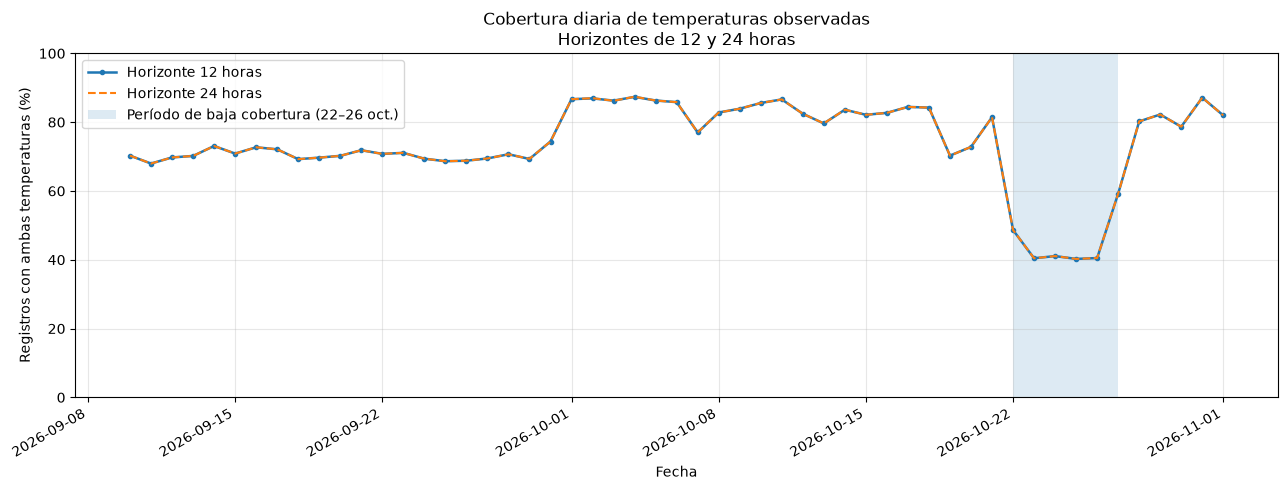

In [17]:

# ==========================================
# 16. EVOLUCIÓN TEMPORAL DE LA COBERTURA
# ==========================================

# Ordenar cronológicamente los resultados
df_grafico = df_cobertura.sort_values("fecha").copy()

# Crear figura
fig, ax = plt.subplots(figsize=(13, 5))

# Cobertura del horizonte de 12 horas
ax.plot(
    df_grafico["fecha"],
    df_grafico["cobertura_12h_pct"],
    marker="o",
    markersize=3,
    linewidth=1.8,
    label="Horizonte 12 horas"
)

# Cobertura del horizonte de 24 horas
ax.plot(
    df_grafico["fecha"],
    df_grafico["cobertura_24h_pct"],
    linestyle="--",
    linewidth=1.5,
    label="Horizonte 24 horas"
)

# Destacar el período con baja cobertura
ax.axvspan(
    pd.Timestamp("2026-10-22"),
    pd.Timestamp("2026-10-27"),
    alpha=0.15,
    label="Período de baja cobertura (22–26 oct.)"
)

# Configuración del gráfico
ax.set_title(
    "Cobertura diaria de temperaturas observadas\n"
    "Horizontes de 12 y 24 horas"
)

ax.set_xlabel("Fecha")
ax.set_ylabel("Registros con ambas temperaturas (%)")

ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3)
ax.legend()

# Mejorar etiquetas de fechas
fig.autofmt_xdate()

plt.tight_layout()
plt.show()


Veo tres períodos diferenciados:

1) 10 al 30 de septiembre
La cobertura se mantiene relativamente estable, alrededor del 68–74 %. Hay oscilaciones pequeñas, pero no caídas pronunciadas.

2) Primera parte de octubre
La cobertura aumenta, generalmente hasta aproximadamente 80–87 %, aunque aparecen algunos descensos puntuales.

3) 22 al 26 de octubre
Se produce una caída brusca hasta aproximadamente 40–49 %. Posteriormente, la disponibilidad se recupera.

¿Por qué es relevante para Machine Learning?

Si entrenamos sin analizar estos días, podríamos tener una representación desigual de las distintas fechas. También necesitamos comprobar si la reducción de observaciones afecta especialmente a determinadas estaciones


### 16.1. Interpretación de la cobertura temporal

Se representó la evolución diaria del porcentaje de registros con temperaturas pronosticadas y observadas disponibles para los horizontes de 12 y 24 horas.

**Resultados principales:**

- Durante septiembre, la cobertura permaneció relativamente estable, alrededor del 68–74 %.
- A comienzos de octubre se observó un incremento en la disponibilidad de observaciones, con porcentajes que llegaron a superar el 85 %.
- Entre el 22 y el 26 de octubre se detectó una caída pronunciada de la cobertura, alcanzando un mínimo del 40,25 % el 25 de octubre para el horizonte de 12 horas.
- Posteriormente se observó una recuperación de la cobertura.
- Los horizontes de 12 y 24 horas presentaron comportamientos temporales prácticamente coincidentes.

**Interpretación:**

La disponibilidad de observaciones meteorológicas no es constante a lo largo del período analizado.

La caída registrada durante octubre podría influir sobre la composición del conjunto de entrenamiento y evaluación, especialmente si afecta de manera desigual a las estaciones meteorológicas.

**Decisión metodológica:**

Se investigará la distribución de los tipos de emparejamiento y los registros sin observación durante el período de baja cobertura.

No se eliminarán fechas ni se imputarán temperaturas observadas sin una justificación basada en los resultados de la auditoría.


In [18]:

# ==========================================
# 17. INVESTIGACIÓN DE BAJA COBERTURA
# ==========================================

fechas_control = [
    "2026_10_20",
    "2026_10_24",
    "2026_10_28"
]

columnas_analisis = [
    "horizon_target_hours",
    "match_type",
    "temperature_forecast_c",
    "temperature_observed_c"
]

resultados_anomalia = []

for fecha in fechas_control:

    archivo = (
        DATASET_DIR /
        f"forecast_observation_{fecha}.csv"
    )

    # Lectura por bloques para reducir uso de memoria
    for bloque in pd.read_csv(
        archivo,
        usecols=columnas_analisis,
        chunksize=100_000
    ):

        # Analizar solo el horizonte de 12 horas
        bloque = bloque[
            bloque["horizon_target_hours"] == 12
        ].copy()

        bloque["temperaturas_validas"] = (
            bloque["temperature_forecast_c"].notna()
            & bloque["temperature_observed_c"].notna()
        )

        resumen_bloque = (
            bloque.groupby("match_type", dropna=False)
            .agg(
                registros=("temperaturas_validas", "size"),
                validos=("temperaturas_validas", "sum")
            )
            .reset_index()
        )

        resumen_bloque["fecha"] = fecha

        resultados_anomalia.append(resumen_bloque)

# Unificar los resultados de los bloques
df_anomalia = pd.concat(
    resultados_anomalia,
    ignore_index=True
)

df_anomalia = (
    df_anomalia
    .groupby(["fecha", "match_type"], dropna=False)
    [["registros", "validos"]]
    .sum()
    .reset_index()
)

# Calcular registros sin ambas temperaturas
df_anomalia["sin_temperaturas_completas"] = (
    df_anomalia["registros"]
    - df_anomalia["validos"]
)

df_anomalia["porcentaje_validos"] = (
    df_anomalia["validos"]
    / df_anomalia["registros"]
    * 100
)

print("Comparación de emparejamientos por fecha:")

display(df_anomalia.round(2))


Comparación de emparejamientos por fecha:


,fecha,match_type,registros,validos,sin_temperaturas_completas,porcentaje_validos
0,2026_10_20,fallback,1063,872,191,82.03
1,2026_10_20,interval,9482,8196,1286,86.44
2,2026_10_20,unmatched,1911,0,1911,0.00
3,2026_10_24,fallback,490,447,43,91.22
4,2026_10_24,interval,4989,4668,321,93.57
5,2026_10_24,unmatched,6977,0,6977,0.00
6,2026_10_28,fallback,1753,1539,214,87.79
7,2026_10_28,interval,9646,8453,1193,87.63
8,2026_10_28,unmatched,1057,0,1057,0.00


In [19]:

# ==========================================
# 18. ESTACIONES AFECTADAS POR LA BAJA COBERTURA
# ==========================================

resultados_estaciones = []

for fecha in fechas_control:

    archivo = (
        DATASET_DIR /
        f"forecast_observation_{fecha}.csv"
    )

    df_est = pd.read_csv(
        archivo,
        usecols=[
            "station_id",
            "horizon_target_hours",
            "match_type",
            "temperature_observed_c"
        ]
    )

    # Analizar el horizonte de 12 horas
    df_est = df_est[
        df_est["horizon_target_hours"] == 12
    ].copy()

    # Identificar emparejamientos fallidos
    df_est["unmatched"] = (
        df_est["match_type"] == "unmatched"
    )

    # Resumir por estación
    por_estacion = (
        df_est.groupby("station_id", dropna=False)
        .agg(
            registros=("unmatched", "size"),
            sin_emparejamiento=("unmatched", "sum"),
            observaciones_validas=(
                "temperature_observed_c",
                "count"
            )
        )
    )

    # Clasificar estaciones
    estaciones_totalmente_unmatched = (
        por_estacion["sin_emparejamiento"]
        == por_estacion["registros"]
    ).sum()

    estaciones_parcialmente_unmatched = (
        (por_estacion["sin_emparejamiento"] > 0)
        & (por_estacion["sin_emparejamiento"]
           < por_estacion["registros"])
    ).sum()

    estaciones_sin_observaciones = (
        por_estacion["observaciones_validas"] == 0
    ).sum()

    resultados_estaciones.append({
        "fecha": fecha,
        "estaciones_totales": len(por_estacion),
        "totalmente_unmatched": estaciones_totalmente_unmatched,
        "parcialmente_unmatched": estaciones_parcialmente_unmatched,
        "sin_observaciones_validas": estaciones_sin_observaciones
    })

df_estaciones_anomalia = pd.DataFrame(
    resultados_estaciones
)

print("Impacto de la anomalía sobre las estaciones:")
display(df_estaciones_anomalia)


Impacto de la anomalía sobre las estaciones:


,fecha,estaciones_totales,totalmente_unmatched,parcialmente_unmatched,sin_observaciones_validas
0,2026_10_20,519,9,510,11
1,2026_10_24,519,281,102,281
2,2026_10_28,519,6,428,8



### 18.1. Investigación de la caída de cobertura de octubre

Se investigó la disminución de cobertura observada entre el 22 y el 26 de octubre de 2026, utilizando el horizonte de predicción de 12 horas.

Se compararon los días 20, 24 y 28 de octubre.

**Resultados:**

- Las tres fechas conservaron 519 estaciones meteorológicas.
- El 20 de octubre, 9 estaciones presentaron exclusivamente registros `unmatched`.
- El 24 de octubre, 281 estaciones presentaron exclusivamente registros `unmatched`, equivalentes al 54,1 % de las estaciones.
- El 28 de octubre, esa cantidad descendió a 6 estaciones.
- El 24 de octubre también se identificaron 281 estaciones sin temperaturas observadas válidas.

**Interpretación:**

La caída de cobertura coincide principalmente con un aumento considerable de registros sin observaciones emparejadas, distribuido entre numerosas estaciones.

La evidencia no permite determinar la causa técnica exacta de la anomalía.

**Decisión metodológica:**

No se eliminará automáticamente el período afectado.

Se conservará el orden cronológico de los registros y se examinará la sensibilidad de los resultados a los cambios de cobertura durante la evaluación temporal.

Los registros sin temperatura observada no se utilizarán para el entrenamiento supervisado, dado que no permiten calcular el error real de predicción.



## 19. Criterio de exclusión del período anómalo

Durante la auditoría del conjunto de 53 archivos CSV se identificó una disminución pronunciada de la cobertura de observaciones meteorológicas entre el 22 y el 26 de octubre de 2026.

### Evidencia encontrada

- La cobertura diaria mínima fue del 40,25 %, registrada el 25 de octubre para el horizonte de 12 horas.
- El 24 de octubre se identificaron 6.977 registros de tipo `unmatched`, frente a 1.911 el 20 de octubre.
- El 24 de octubre, 281 de las 519 estaciones meteorológicas presentaron exclusivamente registros `unmatched` para el horizonte de 12 horas.
- La cobertura volvió a aumentar después del período analizado.

### Interpretación

La caída de cobertura se encuentra asociada principalmente con el incremento de registros sin observación emparejada.

La anomalía afecta a numerosas estaciones, por lo que no se limita a algunos registros aislados.

Los resultados disponibles no permiten identificar la causa técnica exacta de la pérdida de emparejamientos.

### Decisión metodológica

Siguiendo el criterio establecido por el docente, se excluyen del análisis principal los archivos correspondientes al período comprendido entre el 22 y el 26 de octubre de 2026, inclusive.

Esta decisión busca evitar que un período con cobertura excepcionalmente baja condicione los resultados del análisis exploratorio, el entrenamiento y la evaluación de los modelos.

Los archivos originales se conservarán sin modificaciones y la exclusión se realizará mediante filtros reproducibles.

El conjunto de trabajo estará formado por 48 archivos CSV.

La separación de entrenamiento y prueba respetará el orden cronológico, conservando el intervalo excluido como una discontinuidad temporal. No se construirán lags utilizando desplazamientos de filas que ignoren esa discontinuidad.

### Limitaciones

La exclusión reduce el período de estudio y podría introducir sesgos si la falta de observaciones estuviera relacionada con condiciones meteorológicas particulares.

Por ello, las conclusiones del modelado se limitarán al período y a las observaciones efectivamente evaluadas.


In [20]:

# ==========================================
# 20. SELECCIÓN DE ARCHIVOS PARA EL ANÁLISIS
# ==========================================

# Período excluido por criterio metodológico
FECHA_INICIO_EXCLUSION = pd.Timestamp("2026-10-22")
FECHA_FIN_EXCLUSION = pd.Timestamp("2026-10-26")

# Utilizar la auditoría que ya tenemos en memoria
df_periodo_excluido = df_cobertura[
    df_cobertura["fecha"].between(
        FECHA_INICIO_EXCLUSION,
        FECHA_FIN_EXCLUSION
    )
].copy()

df_periodo_analisis = df_cobertura[
    ~df_cobertura["fecha"].between(
        FECHA_INICIO_EXCLUSION,
        FECHA_FIN_EXCLUSION
    )
].copy()

# Seleccionar los archivos originales que sí utilizaremos
nombres_seleccionados = set(
    df_periodo_analisis["archivo"]
)

archivos_analisis = [
    archivo for archivo in archivos
    if archivo.name in nombres_seleccionados
]

# Comprobar la selección
print("Archivos originales:", len(archivos))
print("Archivos excluidos:", len(df_periodo_excluido))
print("Archivos para análisis:", len(archivos_analisis))

print("\nFechas excluidas:")
display(
    df_periodo_excluido[
        ["fecha", "registros_12h", "validos_12h",
         "cobertura_12h_pct"]
    ]
)

print("\nRegistros disponibles para modelado principal:")

print(
    "Horizonte 12 h:",
    df_periodo_analisis["interval_validos_12h"].sum()
)

print(
    "Horizonte 24 h:",
    df_periodo_analisis["interval_validos_24h"].sum()
)

print("\nLos archivos originales no fueron modificados.")


Archivos originales: 53
Archivos excluidos: 5
Archivos para análisis: 48

Fechas excluidas:


,fecha,registros_12h,validos_12h,cobertura_12h_pct
42,2026-10-22,12456,6059,48.643224
43,2026-10-23,12456,5036,40.430315
44,2026-10-24,12456,5115,41.064547
45,2026-10-25,12456,5013,40.245665
46,2026-10-26,12456,5044,40.494541



Registros disponibles para modelado principal:
Horizonte 12 h: 427009
Horizonte 24 h: 427000

Los archivos originales no fueron modificados.


In [21]:

# ==========================================
# 21. VERIFICACIÓN DEL LÍMITE DE EXCLUSIÓN
# ==========================================

archivo_borde = (
    DATASET_DIR /
    "forecast_observation_2026_10_21.csv"
)

df_borde = pd.read_csv(
    archivo_borde,
    usecols=[
        "horizon_target_hours",
        "snapshot_time_utc",
        "target_time_utc"
    ],
    low_memory=False
)

# Seleccionar únicamente los horizontes estudiados
df_borde = df_borde[
    df_borde["horizon_target_hours"].isin([12, 24])
].copy()

# Obtener la fecha objetivo en UTC
df_borde["fecha_objetivo"] = pd.to_datetime(
    df_borde["target_time_utc"],
    utc=True,
    errors="coerce"
).dt.date

print("Fechas objetivo de los pronósticos del 21 de octubre:")

display(
    pd.crosstab(
        df_borde["fecha_objetivo"],
        df_borde["horizon_target_hours"]
    )
)

# Comprobar solapamiento con el período excluido
fecha_inicio = pd.Timestamp("2026-10-22").date()
fecha_fin = pd.Timestamp("2026-10-26").date()

solapamiento = df_borde[
    df_borde["fecha_objetivo"].between(
        fecha_inicio,
        fecha_fin
    )
]

print("\nPronósticos con fecha objetivo en el período excluido:")
print(len(solapamiento))


Fechas objetivo de los pronósticos del 21 de octubre:


horizon_target_hours,12,24
fecha_objetivo,,
2026-10-21,12456,12456



Pronósticos con fecha objetivo en el período excluido:
0


In [22]:

# ==========================================
# 22. VERIFICACIÓN DEL LÍMITE POSTERIOR
# ==========================================

archivo_posterior = (
    DATASET_DIR /
    "forecast_observation_2026_10_27.csv"
)

df_posterior = pd.read_csv(
    archivo_posterior,
    usecols=[
        "horizon_target_hours",
        "target_time_utc"
    ],
    low_memory=False
)

df_posterior = df_posterior[
    df_posterior["horizon_target_hours"].isin([12, 24])
].copy()

df_posterior["fecha_objetivo"] = pd.to_datetime(
    df_posterior["target_time_utc"],
    utc=True,
    errors="coerce"
).dt.date

print("Fechas objetivo del archivo del 27 de octubre:")

display(
    pd.crosstab(
        df_posterior["fecha_objetivo"],
        df_posterior["horizon_target_hours"],
        dropna=False
    )
)

# Comprobar posible solapamiento
solapamiento_posterior = df_posterior[
    df_posterior["fecha_objetivo"].between(
        pd.Timestamp("2026-10-22").date(),
        pd.Timestamp("2026-10-26").date()
    )
]

print("\nRegistros cuyo objetivo cae en el período excluido:")
print(len(solapamiento_posterior))

print("\nFechas objetivo faltantes:")
print(df_posterior["fecha_objetivo"].isna().sum())


Fechas objetivo del archivo del 27 de octubre:


horizon_target_hours,12,24
fecha_objetivo,,
2026-10-27,12456,12456



Registros cuyo objetivo cae en el período excluido:
0

Fechas objetivo faltantes:
0


¿Por qué esta comprobación?
Queremos asegurarnos de que la exclusión de los días 22–26 de octubre no deje accidentalmente registros de esas fechas en los archivos inmediatamente anteriores o posteriores.

Estos controles verifican los límites, aunque no sustituyen una validación completa de fechas y duplicados entre archivos antes de entrenar.